# Entrega 2 (parte A) — Preparación de los datos
**Proyecto:** Predicción de cancelaciones de reservas hoteleras
**Curso:** Aprendizaje Máquina I — Maestría en Ciencia de Datos, Universidad Panamericana

Este cuaderno cubre la fase 3 de CRISP-DM y aplica la bitácora de decisiones de la Entrega 1
(`01_EDA.ipynb`, §11):

1. **Limpieza:** manejo de faltantes y corrección de errores.
2. **Ingeniería de características:** nuevas variables a partir de las existentes.
3. **Partición temporal** en entrenamiento y prueba.
4. **Transformación:** imputación, log, escalado y codificación, ajustados *solo* con entrenamiento.

**Principio de diseño.** Se separa lo que *no aprende* de los datos (reglas fila por fila:
limpieza e ingeniería de características, en `src/hoteles/datos.py`) de lo que *sí aprende*
(medianas, percentiles, medias, categorías frecuentes, en `src/hoteles/preprocesamiento.py`).
Lo primero puede aplicarse antes de partir sin fuga de información; lo segundo vive dentro de un
`Pipeline` que se ajusta únicamente con el conjunto de entrenamiento. Ambos módulos se reutilizan
tal cual en el servidor que despliega el modelo, de modo que entrenamiento y servicio coinciden.

## 0. Configuración

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from hoteles.datos import (CAT, NUM_NUEVAS, Y, cargar_crudos, columnas_modelo, crear_variables,
                           limpiar)
from hoteles.estilo import AZUL, GRIS, NARANJA, TINTA, TINTA2, aplicar_estilo, guardar, pct
from hoteles.preprocesamiento import construir_preprocesador

SEED = 42
RAIZ = Path("..").resolve()
DATOS = RAIZ / "data" / "raw" / "hotels.csv"
PROC = RAIZ / "data" / "processed"
FIG = RAIZ / "report" / "figuras"
TAB = RAIZ / "report" / "tablas"
for p in (PROC, FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)
aplicar_estilo()

## 1. Carga

In [2]:
df = cargar_crudos(DATOS)
assert df.shape == (119390, 32), "El archivo no coincide con la versión de la Entrega 1"
df.shape

(119390, 32)

## 2. Limpieza

Cada tratamiento corresponde a una decisión de la bitácora de la Entrega 1:

| Problema | Tratamiento | Bitácora |
|---|---|---|
| `reservation_status(_date)`, `assigned_room_type` revelan el desenlace | Se eliminan | #1 |
| `arrival_date_year` no se repite en producción | Se elimina como predictor (se conserva la fecha para partir) | #4 |
| `agent` / `company` nulos = *no aplica* | Categorías «Sin agente» / «Sin empresa» | #5 |
| `country` nulo informativo | Categoría «Desconocido» | #6 |
| `children` con 4 nulos | Imputación con la mediana **dentro del Pipeline** | #7 |
| ADR = 5,400 y ADR < 0 | Recorte a [0, p99.9] **dentro del Pipeline** | #8 |
| 180 reservas con cero huéspedes | Se eliminan (operativamente imposibles) | #9 |
| `meal` = *Undefined* | Se recodifica como `SC` (ambas significan "sin plan") | Diccionario |
| 26.8 % de filas duplicadas | No se eliminan: se guarda una **firma de grupo** para validación agrupada | #3 |

In [3]:
dl, bitacora = limpiar(df)
print(f"Filas: {len(df):,} -> {len(dl):,}  (eliminadas: {len(df) - len(dl):,})")
print(f"Columnas: {df.shape[1]} -> {dl.shape[1]}")
bitacora

Filas: 119,390 -> 119,210  (eliminadas: 180)
Columnas: 32 -> 30


,problema,tratamiento,filas
0,children nulo,Se deja nulo; se imputa con la mediana dentro ...,4
1,country nulo,Categoría «Desconocido» (la nulidad es informa...,488
2,agent nulo,Categoría «Sin agente» (no aplica),16340
3,company nulo,Categoría «Sin empresa» (no aplica),112593
4,meal = Undefined,Se recodifica como SC (sin plan),1169
5,Cero huéspedes,Se eliminan (reservas imposibles),180
6,ADR < 0 o ADR atípico,"Recorte a [0, p99.9] ajustado en entrenamiento",2


In [4]:
with open(TAB / "limpieza.tex", "w") as f:
    for _, r in bitacora.iterrows():
        f.write(f"{r['problema'].replace('_', chr(92) + '_')} & {r['tratamiento']} & {r['filas']:,} \\\\\n")

nulos = dl.isna().sum()
print("Nulos restantes:", nulos[nulos > 0].to_dict())
print("meal:", sorted(dl["meal"].unique()))
print("agent más frecuentes:", dl["agent"].value_counts().head(4).to_dict())
tam = dl.groupby("grupo").size()
print(f"Grupos de duplicados: {dl['grupo'].nunique():,} grupos para {len(dl):,} filas; "
      f"filas en grupos de tamaño > 1: {(tam[tam > 1]).sum():,}; grupo más grande: {tam.max()}")

Nulos restantes: {'children': 4}
meal: ['BB', 'FB', 'HB', 'SC']
agent más frecuentes: {'A9': 31922, 'Sin agente': 16280, 'A240': 13922, 'A1': 7187}
Grupos de duplicados: 87,230 grupos para 119,210 filas; filas en grupos de tamaño > 1: 40,141; grupo más grande: 180


**Lectura:** la limpieza solo elimina 180 filas (0.15 %). Los nulos que quedan son los 4 de
`children`, que se imputan dentro del Pipeline. La columna `grupo` identifica filas idénticas en
las 32 columnas originales: se usará con `StratifiedGroupKFold` para que copias idénticas no
queden a la vez en un pliegue de entrenamiento y en uno de validación.

## 3. Ingeniería de características

| Variable nueva | Construcción | Por qué |
|---|---|---|
| `noches` | fin de semana + entre semana | Duración total de la estancia |
| `huespedes` | adultos + niños + bebés | Tamaño del grupo |
| `estancia_cero` | `noches == 0` | *Day-use*: casi nunca se cancela (4.9 % en el EDA) |
| `proporcion_fin_semana` | noches de fin de semana / noches | Ocio vs. negocios |
| `tiene_ninos` | niños + bebés > 0 | Viaje familiar |
| `mes_sin`, `mes_cos` | ángulo del mes en el círculo | Estacionalidad cíclica (dic. y ene. quedan cerca) |
| `dia_semana`, `llegada_fin_semana` | día de la semana de la **fecha de llegada** | Variable que no existía: se deriva de año, mes y día |
| `tiene_agente`, `tiene_empresa` | `agent` / `company` ≠ "Sin…" | Bandera explícita de canal (bitácora #5) |
| `historial_reservas` | cancelaciones previas + no canceladas | Experiencia del cliente con el hotel |
| `tasa_cancelacion_previa` | cancelaciones previas / historial | Comportamiento pasado normalizado |
| `adr_por_persona` | ADR / huéspedes | Precio relativo al tamaño del grupo |
| `frecuencia_agente` | proporción de reservas de entrenamiento hechas por esa agencia | Prometida en la Entrega 1 (§IV): resume en un número a 330 agencias; se **aprende** del entrenamiento, por eso se calcula dentro del Pipeline (§5) |

Es el análogo, en este problema, de convertir una fecha de nacimiento en una edad: la fecha de
llegada se convierte en día de la semana y en un ángulo de temporada, y los conteos de historial
se convierten en una tasa.

In [5]:
d = crear_variables(dl)
filas = []
for c in NUM_NUEVAS:
    rho = spearmanr(d[c], d[Y])[0]
    filas.append((c, d[c].nunique(), d[c].mean(), rho))
nuevas = pd.DataFrame(filas, columns=["variable", "valores distintos", "media", "rho Spearman con objetivo"])
nuevas.sort_values("rho Spearman con objetivo", key=abs, ascending=False).round(3)

,variable,valores distintos,media,rho Spearman con objetivo
11,tasa_cancelacion_previa,111,0.050,0.273
10,historial_reservas,77,0.224,0.155
8,tiene_agente,2,0.863,0.102
9,tiene_empresa,2,0.057,-0.100
2,estancia_cero,2,0.005,-0.051
1,huespedes,14,1.971,0.050
6,mes_cos,11,-0.144,-0.049
0,noches,42,3.426,0.037
7,llegada_fin_semana,2,0.434,0.017
5,mes_sin,11,-0.056,-0.014


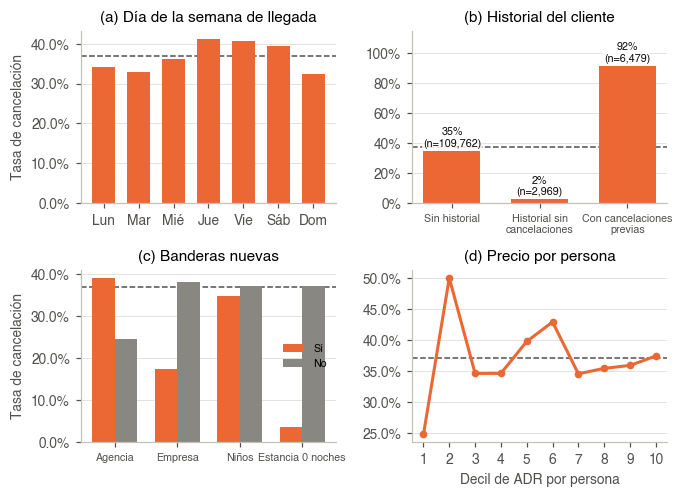

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(6.3, 4.6))
tasa_global = d[Y].mean()

ax = axes[0, 0]
t = d.groupby("dia_semana")[Y].mean().reindex(["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"])
ax.bar([s[:3] for s in t.index], t.values, color=NARANJA, width=0.65)
ax.set_title("(a) Día de la semana de llegada")

ax = axes[0, 1]
hist = np.select([d["historial_reservas"] == 0, d["previous_cancellations"] == 0],
                 ["Sin historial", "Historial sin\ncancelaciones"], "Con cancelaciones\nprevias")
t = d.groupby(hist)[Y].agg(["mean", "size"]).loc[["Sin historial", "Historial sin\ncancelaciones", "Con cancelaciones\nprevias"]]
ax.bar(t.index, t["mean"], color=NARANJA, width=0.65)
for i, (m, n) in enumerate(zip(t["mean"], t["size"])):
    ax.text(i, m + 0.03, f"{m:.0%}\n(n={n:,})", ha="center", fontsize=7, color=TINTA,
            bbox=dict(facecolor="white", edgecolor="none", pad=0.5, alpha=0.85))
ax.set_ylim(0, 1.15)
ax.tick_params(axis="x", labelsize=7)
ax.set_title("(b) Historial del cliente")

ax = axes[1, 0]
etq = [("tiene_agente", "Agencia"), ("tiene_empresa", "Empresa"), ("tiene_ninos", "Niños"), ("estancia_cero", "Estancia 0 noches")]
x = np.arange(len(etq))
si = [d.loc[d[c] == 1, Y].mean() for c, _ in etq]
no = [d.loc[d[c] == 0, Y].mean() for c, _ in etq]
ax.bar(x - 0.18, si, 0.36, color=NARANJA, label="Sí")
ax.bar(x + 0.18, no, 0.36, color=GRIS, label="No")
ax.set_xticks(x, [e for _, e in etq], fontsize=7)
ax.legend(fontsize=7)
ax.set_title("(c) Banderas nuevas")

ax = axes[1, 1]
dec = pd.qcut(d["adr_por_persona"].clip(upper=d["adr_por_persona"].quantile(.999)), 10, duplicates="drop")
t = d.groupby(dec, observed=True)[Y].mean()
ax.plot(range(1, len(t) + 1), t.values, color=NARANJA, marker="o", lw=2, ms=4)
ax.set_xticks(range(1, len(t) + 1))
ax.set_xlabel("Decil de ADR por persona")
ax.set_title("(d) Precio por persona")

for ax in axes.flat:
    ax.axhline(tasa_global, color=TINTA2, lw=1, ls="--", zorder=0)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
    ax.grid(axis="x", visible=False)
axes[0, 0].set_ylabel("Tasa de cancelación")
axes[1, 0].set_ylabel("Tasa de cancelación")
fig.tight_layout()
guardar(fig, FIG, "fig8_variables_nuevas")

**Insight:** la variable nueva más informativa es `tasa_cancelacion_previa` (ρ = 0.27, igual que
`previous_cancellations` pero acotada en [0, 1]): los clientes con historial sin cancelaciones
casi nunca cancelan (2 %), y los que ya cancelaron antes vuelven a cancelar 92 % de las veces
(panel b). Las banderas de canal separan bien: con agencia 39 % vs 25 % sin agencia; con
empresa 17 % vs 38 % (panel c). Las estancias de cero noches cancelan solo 3.6 %. El día de
llegada aporta poco (de 32 % a 41 %) y el ADR por persona no tiene relación monótona con el
objetivo (panel d): ρ ≈ 0, pero el primer decil (cortesías y tarifas corporativas) cancela 25 %
contra 50 % del segundo; un modelo de árboles puede aprovechar esa no linealidad, una regresión
logística no. Las variables con ρ ≈ 0 no se descartan aquí: la selección la harán la
regularización y la importancia por permutación en el modelado.

## 4. Partición temporal en entrenamiento y prueba

Bitácora #4: la tasa de cancelación tiene deriva temporal, así que una partición aleatoria
mezclaría el futuro con el pasado. Se reservan las **llegadas a partir del 1 de mayo de 2017**
(los últimos 4 meses, ≈ 19 % de los datos) como prueba. Es exactamente la situación de uso real:
entrenar con el histórico y predecir reservas futuras. La prueba se usa **una sola vez**, al final
del modelado; toda selección de modelos e hiperparámetros se hace con validación cruzada dentro
del entrenamiento.

In [7]:
CORTE = pd.Timestamp("2017-05-01")
train = d.loc[d["fecha_llegada"] < CORTE].reset_index(drop=True)
test = d.loc[d["fecha_llegada"] >= CORTE].reset_index(drop=True)

part = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba"],
    "Llegadas": [f"{train['fecha_llegada'].min():%d-%m-%Y} a {train['fecha_llegada'].max():%d-%m-%Y}",
                 f"{test['fecha_llegada'].min():%d-%m-%Y} a {test['fecha_llegada'].max():%d-%m-%Y}"],
    "Reservas": [len(train), len(test)],
    "% del total": [len(train) / len(d), len(test) / len(d)],
    "Tasa de cancelación": [train[Y].mean(), test[Y].mean()],
    "Tasa urbano (H2)": [train.loc[train.hotel == "City Hotel", Y].mean(), test.loc[test.hotel == "City Hotel", Y].mean()],
    "Tasa resort (H1)": [train.loc[train.hotel == "Resort Hotel", Y].mean(), test.loc[test.hotel == "Resort Hotel", Y].mean()],
})
with open(TAB / "particion.tex", "w") as f:
    for _, r in part.iterrows():
        f.write(f"{r['Conjunto']} & {r['Llegadas']} & {r['Reservas']:,} & {pct(r['% del total'])} & "
                f"{pct(r['Tasa de cancelación'])} & {pct(r['Tasa urbano (H2)'])} & {pct(r['Tasa resort (H1)'])} \\\\\n")
comunes = len(set(train["grupo"]) & set(test["grupo"]))
print(f"Grupos de duplicados presentes en ambos conjuntos: {comunes}")
part.round(3)

Grupos de duplicados presentes en ambos conjuntos: 0


,Conjunto,Llegadas,Reservas,% del total,Tasa de cancelación,Tasa urbano (H2),Tasa resort (H1)
0,Entrenamiento,01-07-2015 a 30-04-2017,97033,0.814,0.363,0.416,0.260
1,Prueba,01-05-2017 a 31-08-2017,22177,0.186,0.406,0.426,0.362


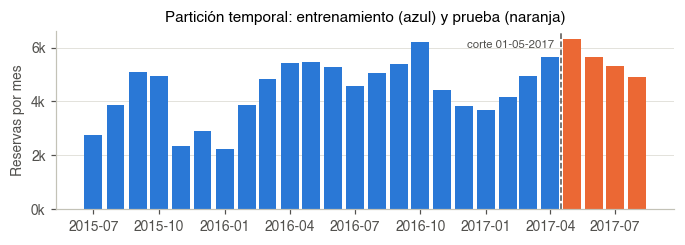

In [8]:
mes = d.assign(mes=d["fecha_llegada"].dt.to_period("M").dt.to_timestamp()).groupby("mes").size()
fig, ax = plt.subplots(figsize=(6.3, 2.3))
ax.bar(mes.index, mes.values, width=25, color=[AZUL if m < CORTE else NARANJA for m in mes.index])
ax.axvline(CORTE - pd.Timedelta(days=15), color=TINTA2, ls="--", lw=1)
ax.text(CORTE - pd.Timedelta(days=25), mes.max() * 0.95, "corte 01-05-2017", ha="right", fontsize=7.5, color=TINTA2)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1000:.0f}k"))
ax.set_ylabel("Reservas por mes")
ax.set_title("Partición temporal: entrenamiento (azul) y prueba (naranja)")
ax.grid(axis="x", visible=False)
fig.tight_layout()
guardar(fig, FIG, "fig9_particion")

**Lectura:** entrenamiento con 97,033 reservas (jul-2015 a abr-2017) y prueba con 22,177 (may a
ago-2017). La tasa de cancelación de prueba (40.6 %) es mayor que la de entrenamiento (36.3 %),
sobre todo en el resort (36.2 % vs 26.0 %): es la deriva temporal que se documentó en el EDA. La
prueba temporal es, por lo tanto, más difícil que una partición aleatoria, pero más honesta.
Además, ningún grupo de duplicados queda partido entre entrenamiento y prueba (las copias
idénticas tienen la misma fecha de llegada), así que la prueba no tiene fuga por duplicados.

## 5. Transformación

Se construyen dos preprocesadores (función `construir_preprocesador`):

- **Lineal** (para la regresión logística): recorte de ADR → mediana → `log1p` en conteos con
  cola larga → estandarización (media 0, desviación 1) → *one-hot*. La logística se entrena por
  descenso por gradiente: si las variables tienen escalas muy distintas (`lead_time` hasta 737,
  banderas 0/1) el gradiente oscila y la penalización L2 castiga de forma desigual a cada
  coeficiente.
- **Árboles** (Random Forest, *Gradient Boosting*): recorte → mediana → *one-hot*. Los árboles
  son invariantes a transformaciones monótonas, así que escalar no cambia sus particiones.

El *one-hot* agrupa en una columna `infrequent` las categorías con menos de 1 % de las filas de
entrenamiento (cientos de agencias y empresas raras) y envía ahí también cualquier categoría
nueva que aparezca en producción. Por defecto se trabaja en el **escenario conservador** (sin
las variables sospechosas de fuga); el escenario completo se evalúa en el cuaderno de modelado.

In [9]:
prep_lineal = construir_preprocesador(lineal=True).fit(train)
prep_arboles = construir_preprocesador(lineal=False).fit(train)
X_lin = prep_lineal.transform(train)
X_arb = prep_arboles.transform(train)
num, cat = columnas_modelo(False)
print(f"Variables de entrada: {len(num)} numéricas + {len(cat)} categóricas = {len(num) + len(cat)}")
print(f"Matriz para el modelo lineal: {X_lin.shape}, nulos: {np.isnan(X_lin).sum()}")
print(f"Matriz para árboles:          {X_arb.shape}, nulos: {np.isnan(X_arb).sum()}")
print("Límites de recorte aprendidos en entrenamiento:", {k: round(v, 1) for k, v in prep_lineal[0].limites_.items()})
ohe = prep_lineal[-1].named_transformers_["categoricas"][-1]
raras = [0 if i is None else len(i) for i in ohe.infrequent_categories_]
pd.DataFrame({"variable": cat,
              "categorías en entrenamiento": [train[c].nunique() for c in cat],
              "agrupadas como infrecuentes": raras,
              "columnas one-hot": [len(c) - r + (r > 0) for c, r in zip(ohe.categories_, raras)]})

Variables de entrada: 28 numéricas + 10 categóricas = 38
Matriz para el modelo lineal: (97033, 81), nulos: 0
Matriz para árboles:          (97033, 81), nulos: 0
Límites de recorte aprendidos en entrenamiento: {'adr': 300.0, 'adr_por_persona': 195.0}


,variable,categorías en entrenamiento,agrupadas como infrecuentes,columnas one-hot
0,hotel,2,0,2
1,meal,4,1,4
2,market_segment,8,3,6
3,distribution_channel,5,2,4
4,reserved_room_type,9,3,7
5,deposit_type,3,1,3
6,agent,316,303,14
7,company,330,329,2
8,customer_type,4,1,4
9,dia_semana,7,0,7


In [10]:
# Variable aprendida: frecuencia histórica de la agencia (ajustada solo con entrenamiento).
frec = prep_lineal.named_steps["frecuencia"]
f_tr = train["agent"].map(frec.frecuencias_)
quintil = pd.qcut(f_tr.rank(method="first"), 5, labels=["Q1 (raras)", "Q2", "Q3", "Q4", "Q5 (frecuentes)"])
print(f"Agencias distintas en entrenamiento: {len(frec.frecuencias_)}; "
      f"agencias de prueba que no aparecen en entrenamiento: {(~test['agent'].isin(frec.frecuencias_.keys())).sum():,} reservas")
print(f"rho de Spearman con el objetivo: {spearmanr(f_tr, train[Y])[0]:.3f}")
train.groupby(quintil, observed=True)[Y].agg(["mean", "size"]).rename(columns={"mean": "tasa de cancelación", "size": "reservas"}).round(3)

Agencias distintas en entrenamiento: 316; agencias de prueba que no aparecen en entrenamiento: 203 reservas
rho de Spearman con el objetivo: 0.005


,tasa de cancelación,reservas
agent,,
Q1 (raras),0.369,19407
Q2,0.309,19406
Q3,0.475,19407
Q4,0.324,19406
Q5 (frecuentes),0.337,19407


**Lectura:** la frecuencia de la agencia no tiene relación monótona con la cancelación
(ρ = 0.005): las agencias del quintil medio cancelan 47.5 % y las más raras y las más
frecuentes, entre 31 % y 37 %. El quintil medio lo forman sobre todo las agencias 240 y 1, que
mezclan reservas en línea con bloques de grupo; el cuarto quintil son casi todas reservas sin
agencia (directas), y el quinto es una sola agencia en línea (la 9, con 25 % de las reservas). La variable se conserva porque los árboles pueden aprovechar relaciones no
monótonas y porque resume en un solo número a las 303 agencias que el *one-hot* manda a la
categoría «infrecuente»; 203 reservas de prueba vienen de agencias nuevas y reciben frecuencia 0.

,lead_time,adr,noches,mes_sin
mean,-0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-2.30,-6.08,-2.81,-1.28
max,1.77,1.80,6.05,1.36


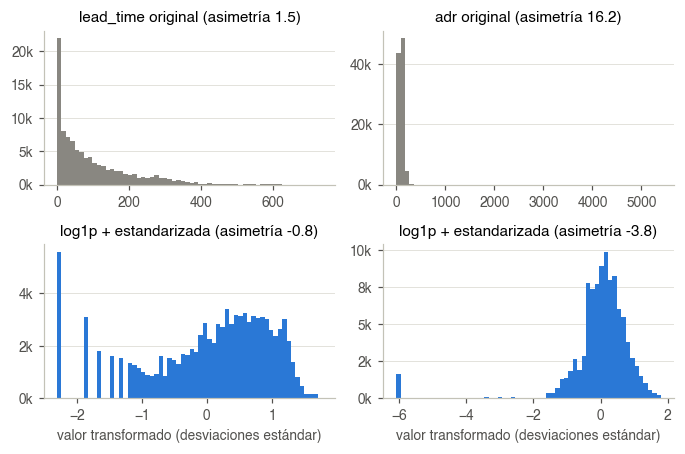

In [11]:
nombres = prep_lineal[-1].get_feature_names_out()
X_lin_df = pd.DataFrame(X_lin, columns=nombres)
fig, axes = plt.subplots(2, 2, figsize=(6.3, 4.2))
for j, c in enumerate(["lead_time", "adr"]):
    crudo = train[c]
    axes[0, j].hist(crudo, bins=60, color=GRIS)
    axes[0, j].set_title(f"{c} original (asimetría {crudo.skew():.1f})")
    axes[1, j].hist(X_lin_df[c], bins=60, color=AZUL)
    axes[1, j].set_title(f"log1p + estandarizada (asimetría {X_lin_df[c].skew():.1f})")
    axes[1, j].set_xlabel("valor transformado (desviaciones estándar)")
for ax in axes.flat:
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1000:.0f}k"))
fig.tight_layout()
guardar(fig, FIG, "fig10_transformacion")
X_lin_df[["lead_time", "adr", "noches", "mes_sin"]].describe().loc[["mean", "std", "min", "max"]].round(2)

**Lectura:** las 38 variables de entrada se convierten en 81 columnas numéricas sin nulos. El
recorte aprendido en entrenamiento acota el ADR en 300 (el 5,400 desaparece) y el ADR por persona
en 195. De 316 agencias, 303 quedan agrupadas como infrecuentes (quedan 14 columnas), y de 330
empresas, 329: el *one-hot* pasa de más de 640 columnas posibles a 53. Tras `log1p` y
estandarización todas las numéricas quedan con media 0 y desviación 1, que es lo que necesita el
descenso por gradiente de la regresión logística. El log reduce mucho la cola derecha: la
asimetría del ADR pasa de 16.2 a −3.8 y la de `lead_time` de 1.5 a −0.8; el signo negativo viene
de la masa de valores en 0 (reservas para el mismo día, cortesías), que el log separa del resto.
No es una distribución normal, pero ya no hay valores a 100 desviaciones de la media que dominen
el gradiente.

## 6. Guardar los conjuntos preparados

Se guardan limpios y con las variables nuevas, pero **sin transformar**: las transformaciones
quedan dentro del Pipeline de cada modelo, que se vuelve a ajustar en cada pliegue de validación
cruzada. Así ningún pliegue de validación "ve" medianas, percentiles o medias calculadas con
datos que no le corresponden.

In [12]:
train.to_parquet(PROC / "train.parquet", index=False)
test.to_parquet(PROC / "test.parquet", index=False)
print(train.shape, test.shape)

(97033, 44) (22177, 44)


## 7. Resumen de la preparación

| Etapa | Resultado |
|---|---|
| Limpieza | 119,390 → 119,210 filas; 3 columnas con fuga y `arrival_date_year` excluidas; nulos con significado convertidos en categorías |
| Ingeniería de características | 14 variables nuevas (fecha → día de la semana y estacionalidad cíclica; historial → tasa; banderas de canal; frecuencia histórica de la agencia) |
| Partición | Temporal: 97,033 entrenamiento / 22,177 prueba (llegadas desde mayo de 2017) |
| Transformación | Pipeline ajustado solo en entrenamiento: recorte ADR, mediana, log1p + escalado (lineal), frecuencia de agencia, *one-hot* con agrupación de raras (< 1 %) |
| Validación | Firma de duplicados en `grupo` para `StratifiedGroupKFold` |

Siguiente cuaderno: `03_modelado.ipynb`.